In [ ]:
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D,Activation, MaxPooling2D, UpSampling2D, Concatenate, Conv2DTranspose, BatchNormalization, Dropout, Lambda, ReLU
from tensorflow.keras.applications import ResNet50
import numpy as np
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping,ReduceLROnPlateau, CSVLogger
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.metrics import MeanIoU
import keras
from keras import ops


In [ ]:
# hiper parametros
height_img = 288
width_img = 288
canais = 3
epochs = 50
batch_size = 16
lr = 0.00001

In [ ]:
# carregando os dados de treino e validação
x_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_train.npy')
y_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_train.npy')
x_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_val.npy')
y_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_val.npy')

In [ ]:
#mesmo bloco de convolução usado na arquitetura U-Net
# essa convolução é a que vai extrair os features maps da imagem com base na quantidade de filtros de entrada
def convolucao(input, filters):
  x = Conv2D(filters,3, padding='same')(input)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  x = Conv2D(filters,3, padding='same')(x)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  return x

In [ ]:
def decoder_resnet(inputs,skips, filters):
    x = Conv2DTranspose(filters, (2,2), strides=2, padding="same")(inputs)
    # pega os pixels de entrada e aumenta a dimensionalidade, diferente da conv que diminui
    x = Concatenate()([x,skips])
    # juntando a camada do encoder com a do decoder
    # como explicado na arquitetura, essas skips servem para que o decoder tenha uma referencia ao aumentar a dimensionalidade e segmentar o objeto corretamente
    # ajuda com que a segmentação esteja no mesmo lugar que o objeto esta na imagem
    x = convolucao(x,filters)
    # bloco de convolução que vai fazer a extração das caracteristicas
    return x

In [ ]:
def resnet50_unet(input_shape):
    inputs = Input(input_shape)
    # camada de entrada da rede

    input = preprocess_input(inputs)
    # o resnet foi treinado em imagens RGB e por isso pegamos esse preprocess propeio do resnet


    resnet = ResNet50(include_top=False, weights="imagenet", input_tensor=input)
    # definimos o modelo resnet, o include diz que queremos apenas as camadas de convolução da estrutura resnet e não a parte de classificação, weights são os pesos ja treinados na base imagenet

    # skips conections que conectam as camadas do encoder e decoder, como vistos na arquitetura U-Net
    # o ponto principal é usar o modelo ja treinado e colocar ele na arquitetura proposta
    s1 = inputs
    # convolução com 512 filtros(feature maps)
    s2 = resnet.get_layer("conv1_relu").output
    # 256 filtros
    s3 = resnet.get_layer("conv2_block3_out").output
    # 128 filtros
    s4 = resnet.get_layer("conv3_block4_out").output
    # 64 filtros

    # BASE DA ARQUITETURA
    b1 = resnet.get_layer("conv4_block6_out").output
    #b1 seria a base da arquitetura U-Net, a parte de baixo na imagem(explicação detalhada no README)

    # DECODER
    # subindo os filtros e diminuindo as saidas, recebe a camada anterior, a conexão de skip e o numero de filtros
    d1 = decoder_resnet(b1, s4, 512)
    d2 = decoder_resnet(d1, s3, 256)
    d3 = decoder_resnet(d2, s2, 128)
    d4 = decoder_resnet(d3, s1, 64)

    outputs = Conv2D(5,1, padding='same',activation='softmax')(d4)
    # camada de saida da rede, adaptado para problema multiclasse

    model = Model(inputs,outputs)
    # juntando tudo

    return model

In [ ]:
model = resnet50_unet((height_img, width_img, canais))
# instanciando o modelo com as entradas, tamanho da imagem e numero de canais

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 288, 288,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 288, 288)  │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 288, 288)  │          0 │ input_layer[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 288, 288)  │          0 │ input_layer[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 288, 288,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 288, 288,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 294, 294,  │          0 │ add[0][0]         │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 144, 144,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 144, 144,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 144, 144,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 146, 146,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 72, 72,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 72, 72,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 72, 72,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 72, 72,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 72, 72,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 72, 72,    │        256 │ conv2_block1_2_c

 Total params: 20,676,805 (78.88 MB)

 Trainable params: 20,642,373 (78.74 MB)

 Non-trainable params: 34,432 (134.50 KB)

In [ ]:
dice = keras.losses.Dice(axis=(0, 1, 2))
# loss dice oficial do keras, com axis=(0, 1, 2) calcula o dice separado para cada uma das 5 classes e depois faz a media
# assim o fundo pesa 1/5 e nao domina como acontece na acuracia
# o dice precisa da mascara em one-hot, no mesmo formato da saida do softmax
ce = keras.losses.SparseCategoricalCrossentropy()

def ce_dice_loss(y_true, y_pred):
    y_true_oh = ops.one_hot(ops.cast(ops.squeeze(y_true, axis=-1), 'int32'), 5)
    # transforma a mascara de inteiros (0 a 4) em one-hot
    return ce(y_true, y_pred) + dice(y_true_oh, y_pred)
    # cross entropy da estabilidade no inicio do treino, dice trata o desbalanceamento entre fundo e lesao


In [ ]:
model.compile(optimizer=Adam(learning_rate=lr), loss=ce_dice_loss, metrics=[MeanIoU(num_classes=5, sparse_y_true=True, sparse_y_pred=False, name='mean_io_u')])
# compilando o modelo com o otimizador Adam, a loss cross entropy + dice e o MeanIoU como medida para avaliar o modelo durante o treino
# a acuracia estava muito alta pois o modelo pode prever totalmente o fundo, que é a classe majoritaria em todas as imagens
# o MeanIoU calcula o IoU de cada classe separadamente e faz a media, assim o fundo pesa igual as doencas
# sparse_y_true=True pois as mascaras estao como inteiros, sparse_y_pred=False pois a saida do modelo sao probabilidades (softmax)
# o name='mean_io_u' garante que o checkpoint encontre a metrica val_mean_io_u mesmo se a celula for rodada mais de uma vez
# a loss soma a cross entropy esparsa (estabilidade) com o dice por classe (trata o desbalanceamento entre fundo e lesao)


In [ ]:
path_model = '/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET50_U-Net/modelo_unet_resnet_dice.keras'


In [ ]:
checkpointer = ModelCheckpoint(path_model, verbose=1, save_best_only=True, monitor='val_mean_io_u', mode='max')
# salva o melhor modelo alcançado durante o treino, medido pelo IoU
# quanto mais proximo de 1 melhor
early_stopper = EarlyStopping(patience = 8, monitor='val_loss')
# para o treino caso após 8 epocas o val_loss nao tenha melhorado
lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=0.000001, verbose=1)
# reduz o learning rate se apos 3 epocas o val_loss nao apresentar melhoras

checks = [checkpointer, lr_reducer, early_stopper]


In [ ]:
# treinando o modelo
treino = model.fit(x_train, y_train,validation_data=(x_val, y_val),epochs=epochs,batch_size=batch_size,callbacks=checks)

Epoch 1/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step - loss: 1.5761 - mean_io_u: 0.3130
Epoch 1: val_mean_io_u improved from None to 0.38048, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET50_U-Net/modelo_unet_resnet_dice.keras

Epoch 1: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET50_U-Net/modelo_unet_resnet_dice.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 126s 426ms/step - loss: 1.4755 - mean_io_u: 0.3332 - val_loss: 1.3794 - val_mean_io_u: 0.3805 - learning_rate: 1.0000e-05
Epoch 2/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 396ms/step - loss: 1.2413 - mean_io_u: 0.3884
Epoch 2: val_mean_io_u improved from 0.38048 to 0.42324, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET50_U-Net/modelo_unet_resnet_dice.keras

Epoch 2: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET50_U-Net/modelo_unet_resnet_d

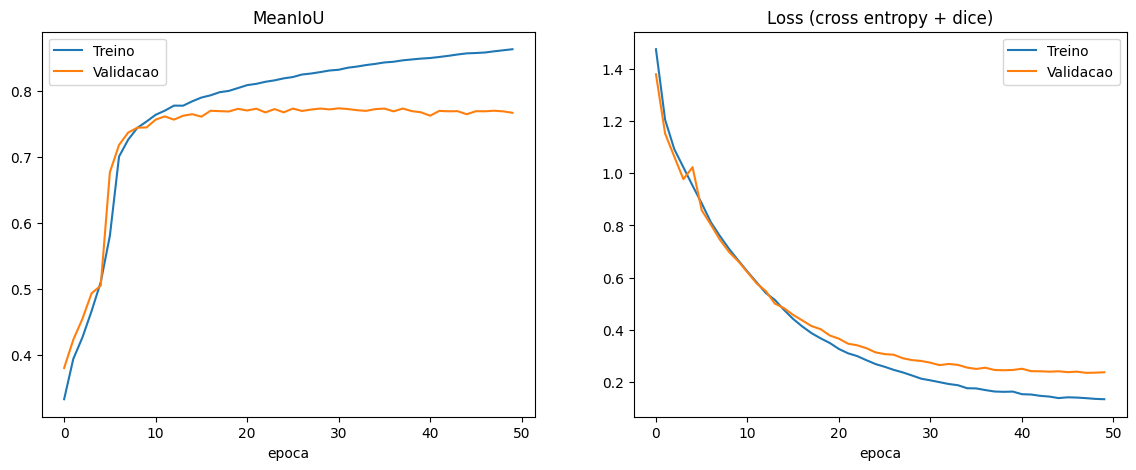

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(treino.history['mean_io_u'], label='Treino')
plt.plot(treino.history['val_mean_io_u'], label='Validacao')
plt.title('MeanIoU')
plt.xlabel('epoca')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(treino.history['loss'], label='Treino')
plt.plot(treino.history['val_loss'], label='Validacao')
plt.title('Loss (cross entropy + dice)')
plt.xlabel('epoca')
plt.legend()

plt.show()
